**DMDc**

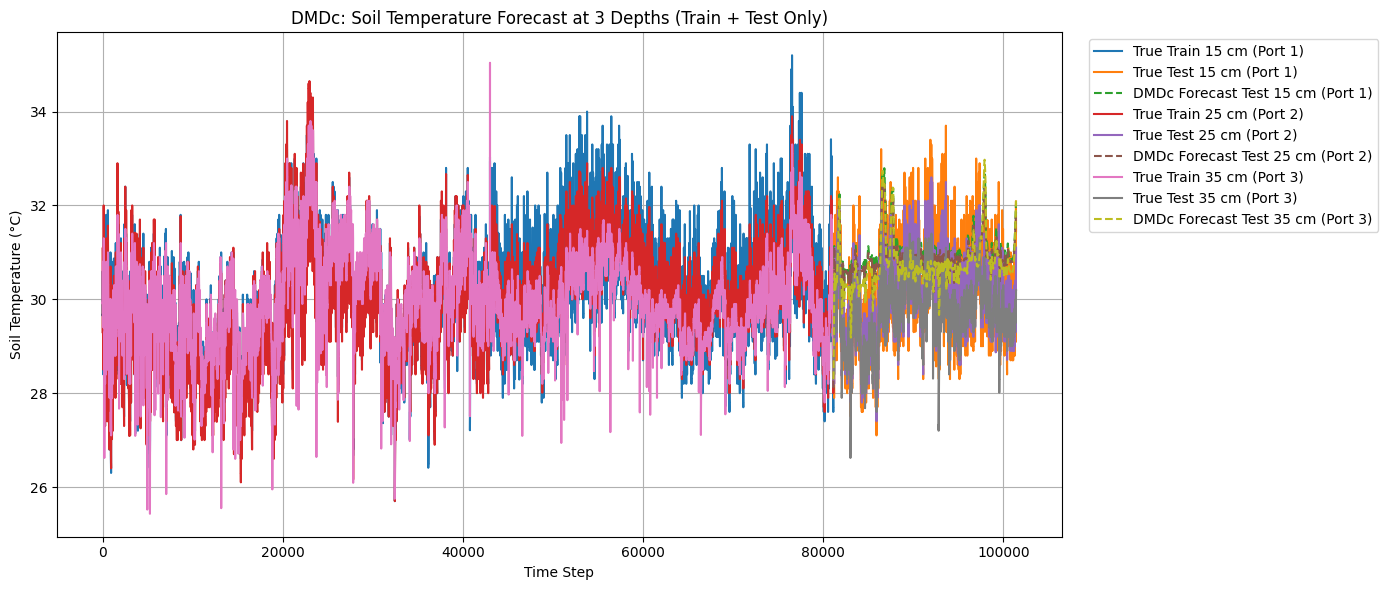


📊 DMDc Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 1.375343 1.159974 3.918599
25 cm (Port 2)  Test 1.205673 1.017976 3.441377
35 cm (Port 3)  Test 1.197804 1.037786 3.525574


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import pinv, LinAlgError
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Extract Inputs (U) and Outputs (Y) ===
def extract_io(df):
    U = df[[
        "Water Content_Port1",
        "Water Content_Port2",
        "Water Content_Port3"
    ]].values.T

    Y = df[[
        "Soil Temperature_Port1",
        "Soil Temperature_Port2",
        "Soil Temperature_Port3"
    ]].values.T

    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw.T).T
Y_train = Y_scaler.fit_transform(Y_train_raw.T).T
U_test = U_scaler.transform(U_test_raw.T).T
Y_test = Y_scaler.transform(Y_test_raw.T).T

# === Construct DMDc training matrices ===
X1 = Y_train[:, :-1]
X2 = Y_train[:, 1:]
U1 = U_train[:, :-1]

# === Remove columns with NaNs ===
mask = ~np.isnan(X1).any(axis=0) & ~np.isnan(X2).any(axis=0) & ~np.isnan(U1).any(axis=0)
X1_clean = X1[:, mask]
X2_clean = X2[:, mask]
U1_clean = U1[:, mask]

Omega = np.vstack((X1_clean, U1_clean))

# === Solve for A and B using least-squares ===
try:
    AB = X2_clean @ pinv(Omega)
    A = AB[:, :X1.shape[0]]
    B = AB[:, X1.shape[0]:]
except LinAlgError as e:
    raise RuntimeError("❌ SVD failed during pinv calculation. Check your data for NaNs or rank deficiency.") from e

# === Forecast ===
def forecast_dmdc(A, B, Y0, U_future, steps):
    Y_pred = np.zeros((Y0.shape[0], steps))
    Y_pred[:, 0] = A @ Y0 + B @ U_future[:, 0]
    for t in range(1, steps):
        Y_pred[:, t] = A @ Y_pred[:, t-1] + B @ U_future[:, t]
    return Y_pred

steps = U_test.shape[1]
Y0 = Y_train[:, -1]  # last timestep of training
Y_pred_scaled = forecast_dmdc(A, B, Y0, U_test, steps)

# === Inverse scale ===
Y_pred = Y_scaler.inverse_transform(Y_pred_scaled.T).T
Y_test_orig = Y_scaler.inverse_transform(Y_test.T).T

# === Plot Forecast ===
depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
n_train = Y_train.shape[1]
n_test = Y_test.shape[1]

time_train = range(n_train)
time_test = range(n_train, n_train + n_test)

plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(time_train, Y_train_raw[i], label=f'True Train {depth_labels[i]}')
    plt.plot(time_test, Y_test_orig[i], label=f'True Test {depth_labels[i]}')
    plt.plot(time_test, Y_pred[i], '--', label=f'DMDc Forecast Test {depth_labels[i]}')

plt.title("DMDc: Soil Temperature Forecast at 3 Depths (Train + Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Evaluation ===
def compute_metrics(true, pred):
    mask = ~np.isnan(true) & ~np.isnan(pred)
    true = true[mask]
    pred = pred[mask]
    if len(true) == 0:
        return np.nan, np.nan, np.nan
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(Y_test_orig[i], Y_pred[i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

# === Display Results ===
metrics_df = pd.DataFrame(metrics)
print("\n📊 DMDc Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**DMD**

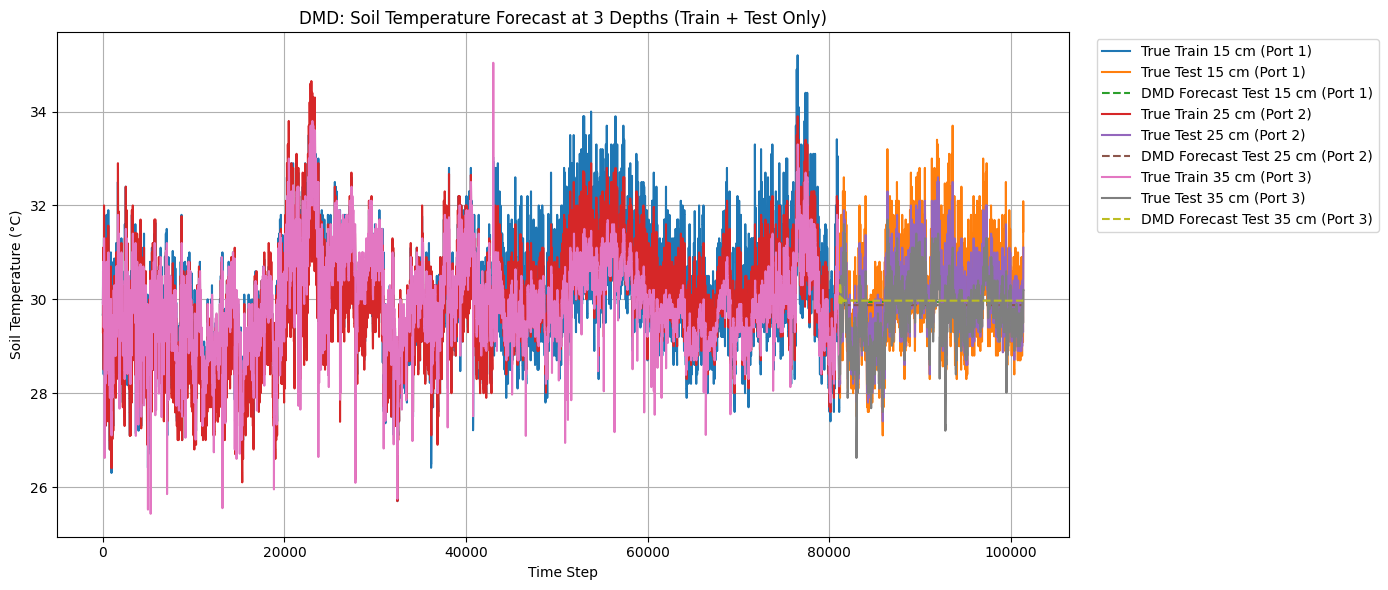


📊 DMD Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 1.060989 0.844488 2.791795
25 cm (Port 2)  Test 0.856438 0.679613 2.259830
35 cm (Port 3)  Test 0.761043 0.593842 2.018294


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import svd, pinv
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Extract only output (Y) data for DMD ===
def extract_Y(df):
    return df[[
        "Soil Temperature_Port1",
        "Soil Temperature_Port2",
        "Soil Temperature_Port3"
    ]].values.T

Y_train_raw = extract_Y(train)
Y_test_raw = extract_Y(test)

# === Normalize ===
scaler = StandardScaler()
Y_train = scaler.fit_transform(Y_train_raw.T).T
Y_test = scaler.transform(Y_test_raw.T).T

# === Remove time steps with NaNs ===
X1 = Y_train[:, :-1]
X2 = Y_train[:, 1:]
valid_mask = ~np.isnan(X1).any(axis=0) & ~np.isnan(X2).any(axis=0)
X1 = X1[:, valid_mask]
X2 = X2[:, valid_mask]

# === Safety check ===
if X1.shape[1] < 2:
    raise ValueError("Not enough clean samples after removing NaNs to perform DMD.")

# === SVD and rank truncation ===
try:
    U, S, Vh = svd(X1, full_matrices=False)
except np.linalg.LinAlgError:
    raise ValueError("SVD failed. Data may still contain problematic values.")

r = min(21, np.linalg.matrix_rank(X1))
U_r = U[:, :r]
S_r = np.diag(S[:r])
V_r = Vh[:r, :]

# === Compute reduced dynamics matrix A_tilde ===
A_tilde = U_r.T @ X2 @ V_r.T @ pinv(S_r)

# === Compute DMD modes and eigenvalues ===
eigvals, W = np.linalg.eig(A_tilde)
Phi = X2 @ V_r.T @ pinv(S_r) @ W

# === Initial amplitudes ===
alpha1 = pinv(Phi) @ X1[:, 0]

# === Forecast future ===
steps = Y_test.shape[1]
time_dynamics = np.array([eigvals**i for i in range(steps)])
Y_pred_scaled = Phi @ (alpha1[:, None] * time_dynamics.T)

# === Inverse scale ===
Y_pred = scaler.inverse_transform(Y_pred_scaled.real.T).T
Y_test_orig = scaler.inverse_transform(Y_test.T).T

# === Plot Forecast ===
depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
n_train = Y_train.shape[1]
n_test = Y_test.shape[1]

time_train = range(n_train)
time_test = range(n_train, n_train + n_test)

plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(time_train, Y_train_raw[i], label=f'True Train {depth_labels[i]}')
    plt.plot(time_test, Y_test_orig[i], label=f'True Test {depth_labels[i]}')
    plt.plot(time_test, Y_pred[i], '--', label=f'DMD Forecast Test {depth_labels[i]}')

plt.title("DMD: Soil Temperature Forecast at 3 Depths (Train + Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Evaluation ===
def compute_metrics(true, pred):
    mask = ~np.isnan(true) & ~np.isnan(pred)
    true = true[mask]
    pred = pred[mask]
    if len(true) == 0:
        return np.nan, np.nan, np.nan
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(Y_test_orig[i], Y_pred[i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

# === Display Results ===
metrics_df = pd.DataFrame(metrics)
print("\n📊 DMD Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**ARIMAX**

/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: Conver

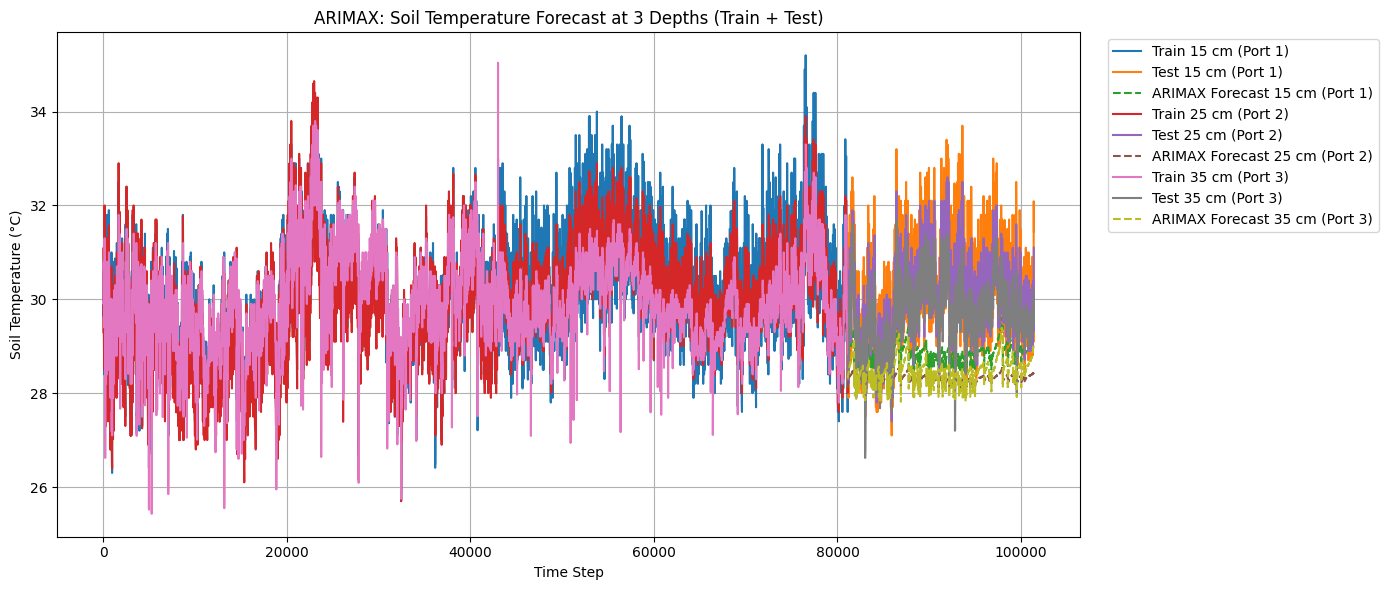


📊 ARIMAX Forecast Evaluation Metrics (Test Only):
         Depth     RMSE      MAE     MAPE
15 cm (Port 1) 1.576960 1.286696 4.186380
25 cm (Port 2) 1.878358 1.695854 5.583710
35 cm (Port 3) 1.400578 1.258322 4.188708


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Prepare target and exogenous variables ===
depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
soil_cols = ["Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"]
water_cols = ["Water Content_Port1", "Water Content_Port2", "Water Content_Port3"]

# === Clean: Replace inf with NaN, then drop rows with NaNs in important cols ===
train.replace([np.inf, -np.inf], np.nan, inplace=True)
test.replace([np.inf, -np.inf], np.nan, inplace=True)
train.dropna(subset=soil_cols + water_cols, inplace=True)
test.dropna(subset=soil_cols + water_cols, inplace=True)

# === Normalize exogenous inputs ===
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train[water_cols])
X_test_scaled = scaler.transform(test[water_cols])

# === Forecast for each depth ===
predictions = []
metrics = {"Depth": [], "RMSE": [], "MAE": [], "MAPE": []}

plt.figure(figsize=(14, 6))
for i in range(3):
    y_train = train[soil_cols[i]].values
    y_test = test[soil_cols[i]].values

    # ARIMAX model
    model = SARIMAX(y_train, exog=X_train_scaled, order=(2,1,2), seasonal_order=(0,0,0,0))
    result = model.fit(disp=False)

    # Forecast with exogenous input
    forecast = result.forecast(steps=len(y_test), exog=X_test_scaled)
    predictions.append(forecast)

    # === Evaluation ===
    rmse = np.sqrt(mean_squared_error(y_test, forecast))
    mae = mean_absolute_error(y_test, forecast)
    mape = np.mean(np.abs((y_test - forecast) / y_test)) * 100

    metrics["Depth"].append(depth_labels[i])
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

    # === Plot ===
    n_train = len(y_train)
    n_test = len(y_test)
    time_train = range(n_train)
    time_test = range(n_train, n_train + n_test)

    plt.plot(time_train, y_train, label=f'Train {depth_labels[i]}')
    plt.plot(time_test, y_test, label=f'Test {depth_labels[i]}')
    plt.plot(time_test, forecast, '--', label=f'ARIMAX Forecast {depth_labels[i]}')

plt.title("ARIMAX: Soil Temperature Forecast at 3 Depths (Train + Test)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Metrics ===
metrics_df = pd.DataFrame(metrics)
print("\n📊 ARIMAX Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**SVR**

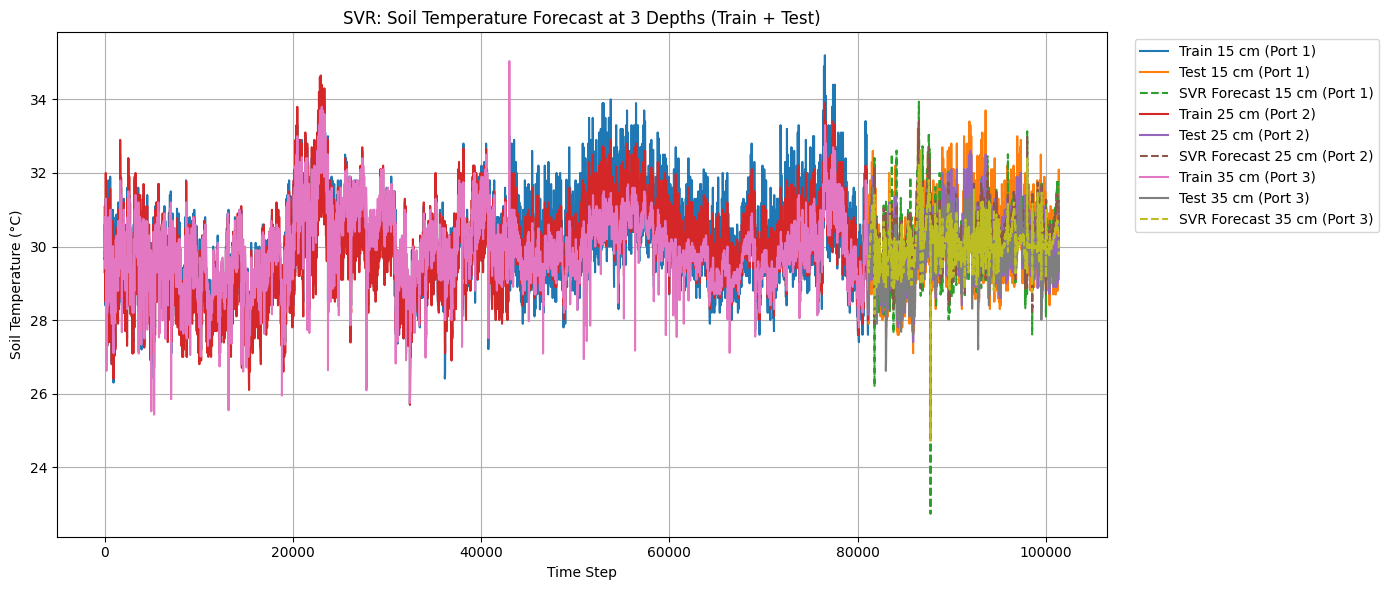


📊 SVR Forecast Evaluation Metrics (Test Only):
         Depth     RMSE      MAE     MAPE
15 cm (Port 1) 1.099320 0.896028 2.992567
25 cm (Port 2) 0.933717 0.767412 2.575212
35 cm (Port 3) 0.808681 0.655809 2.225343


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Define depth labels and columns ===
depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
soil_cols = ["Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"]
water_cols = ["Water Content_Port1", "Water Content_Port2", "Water Content_Port3"]

# === Handle missing values ===
# Forward fill then backward fill (to fill leading/trailing NaNs)
train[soil_cols + water_cols] = train[soil_cols + water_cols].ffill().bfill()
test[soil_cols + water_cols] = test[soil_cols + water_cols].ffill().bfill()

# === Normalize features and targets ===
X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(train[water_cols])
X_test_scaled = X_scaler.transform(test[water_cols])

# === SVR for each depth ===
predictions = []
metrics = {"Depth": [], "RMSE": [], "MAE": [], "MAPE": []}

plt.figure(figsize=(14, 6))
for i in range(3):
    y_train = train[soil_cols[i]].values
    y_test = test[soil_cols[i]].values

    y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()

    # SVR model
    svr = SVR(kernel='rbf', C=100, epsilon=0.1)
    svr.fit(X_train_scaled, y_train_scaled)

    # Forecast
    y_pred_scaled = svr.predict(X_test_scaled)
    y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    predictions.append(y_pred)

    # === Evaluation ===
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    metrics["Depth"].append(depth_labels[i])
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

    # === Plot ===
    n_train = len(y_train)
    n_test = len(y_test)
    time_train = range(n_train)
    time_test = range(n_train, n_train + n_test)

    plt.plot(time_train, y_train, label=f'Train {depth_labels[i]}')
    plt.plot(time_test, y_test, label=f'Test {depth_labels[i]}')
    plt.plot(time_test, y_pred, '--', label=f'SVR Forecast {depth_labels[i]}')

plt.title("SVR: Soil Temperature Forecast at 3 Depths (Train + Test)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Metrics ===
metrics_df = pd.DataFrame(metrics)
print("\n📊 SVR Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**XGBoost**

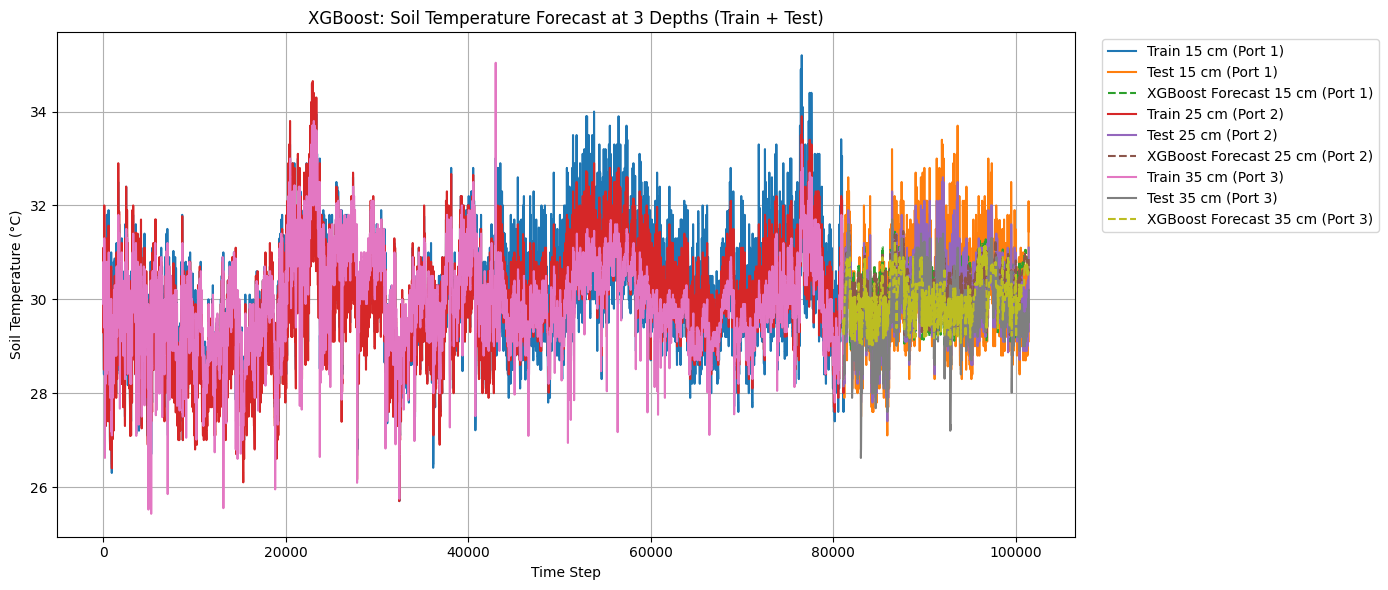


📊 XGBoost Forecast Evaluation Metrics (Test Only):
         Depth     RMSE      MAE     MAPE
15 cm (Port 1) 1.022865 0.845536 2.825818
25 cm (Port 2) 0.843402 0.690614 2.318332
35 cm (Port 3) 0.720785 0.591658 2.006158


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Define depth labels and columns ===
depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
soil_cols = ["Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"]
water_cols = ["Water Content_Port1", "Water Content_Port2", "Water Content_Port3"]

# === Handle missing values (forward + backward fill) ===
train[soil_cols + water_cols] = train[soil_cols + water_cols].ffill().bfill()
test[soil_cols + water_cols] = test[soil_cols + water_cols].ffill().bfill()

# === Normalize features ===
X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(train[water_cols])
X_test_scaled = X_scaler.transform(test[water_cols])

# === Train XGBoost model for each depth ===
predictions = []
metrics = {"Depth": [], "RMSE": [], "MAE": [], "MAPE": []}

plt.figure(figsize=(14, 6))
for i in range(3):
    y_train = train[soil_cols[i]].values
    y_test = test[soil_cols[i]].values

    # === Scale target ===
    y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()

    # === XGBoost Regressor ===
    model = xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
    model.fit(X_train_scaled, y_train_scaled)

    # === Prediction ===
    y_pred_scaled = model.predict(X_test_scaled)
    y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    predictions.append(y_pred)

    # === Evaluation ===
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    metrics["Depth"].append(depth_labels[i])
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

    # === Plot ===
    n_train = len(y_train)
    n_test = len(y_test)
    time_train = range(n_train)
    time_test = range(n_train, n_train + n_test)

    plt.plot(time_train, y_train, label=f'Train {depth_labels[i]}')
    plt.plot(time_test, y_test, label=f'Test {depth_labels[i]}')
    plt.plot(time_test, y_pred, '--', label=f'XGBoost Forecast {depth_labels[i]}')

plt.title("XGBoost: Soil Temperature Forecast at 3 Depths (Train + Test)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
metrics_df = pd.DataFrame(metrics)
print("\n📊 XGBoost Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**DMDc+DMD->MLP**

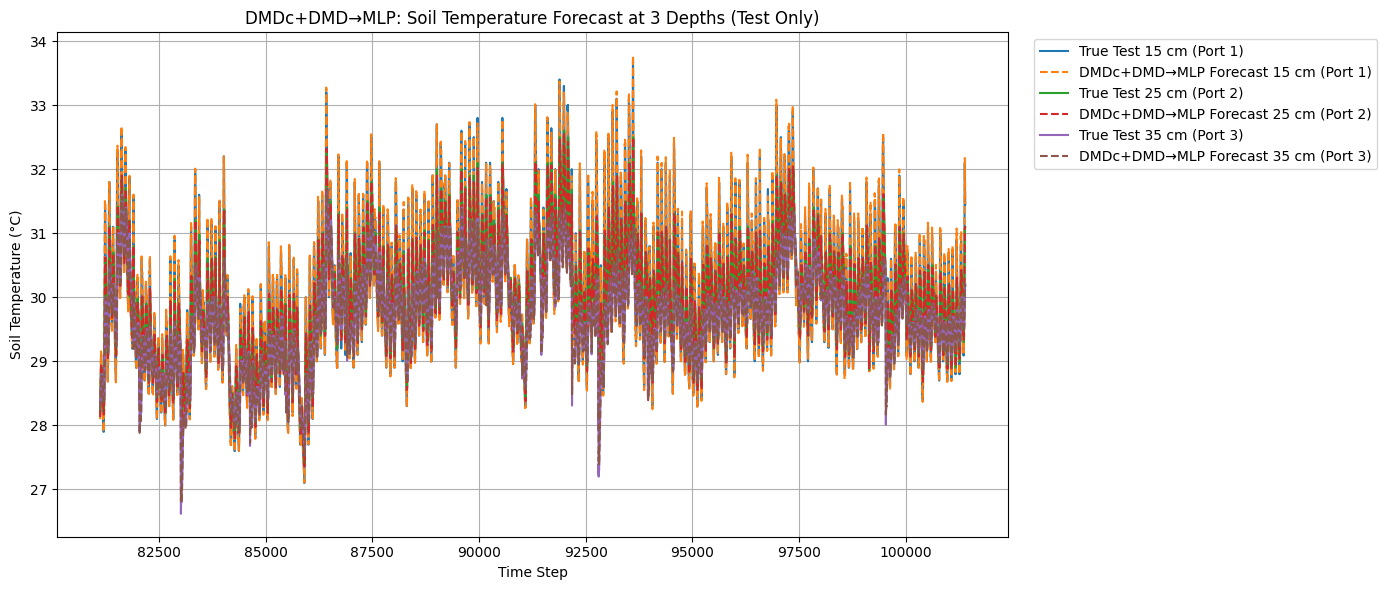


📊 DMDc+DMD→MLP Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.059075 0.044878 0.148840
25 cm (Port 2)  Test 0.043073 0.034127 0.113810
35 cm (Port 3)  Test 0.051477 0.037351 0.125891


In [18]:
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Handle missing values ===
relevant_cols = [
    "Water Content_Port1", "Water Content_Port2", "Water Content_Port3",
    "Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"
]
train[relevant_cols] = train[relevant_cols].ffill().bfill()
test[relevant_cols] = test[relevant_cols].ffill().bfill()

# === Extract Inputs (U) and Outputs (Y) ===
def extract_io(df):
    U = df[[
        "Water Content_Port1",
        "Water Content_Port2",
        "Water Content_Port3"
    ]].values

    Y = df[[
        "Soil Temperature_Port1",
        "Soil Temperature_Port2",
        "Soil Temperature_Port3"
    ]].values

    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# === Prepare features for MLP (DMDc+DMD style) ===
X_train_mlp = np.hstack([U_train[:-1], Y_train[:-1]])  # Feature: [U(t), Y(t)]
y_train_mlp = Y_train[1:]                              # Target: Y(t+1)

X_test_mlp = np.hstack([U_test[:-1], Y_test[:-1]])
y_test_mlp = Y_test[1:]

# === Train MLP Regressor ===
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1000, random_state=42)
mlp.fit(X_train_mlp, y_train_mlp)

# === Predict ===
y_pred_scaled = mlp.predict(X_test_mlp)
y_pred = Y_scaler.inverse_transform(y_pred_scaled)
y_test_orig = Y_scaler.inverse_transform(y_test_mlp)

# === Evaluation ===
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], y_pred[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# === Plot ===
n_train = len(Y_train)
n_test = len(y_test_orig)

plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_train, n_train + n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_train, n_train + n_test), y_pred[:, i], '--', label=f'DMDc+DMD→MLP Forecast {depth_labels[i]}')

plt.title("DMDc+DMD→MLP: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
print("\n📊 DMDc+DMD→MLP Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**DMDc+ARIMAX->MLP**

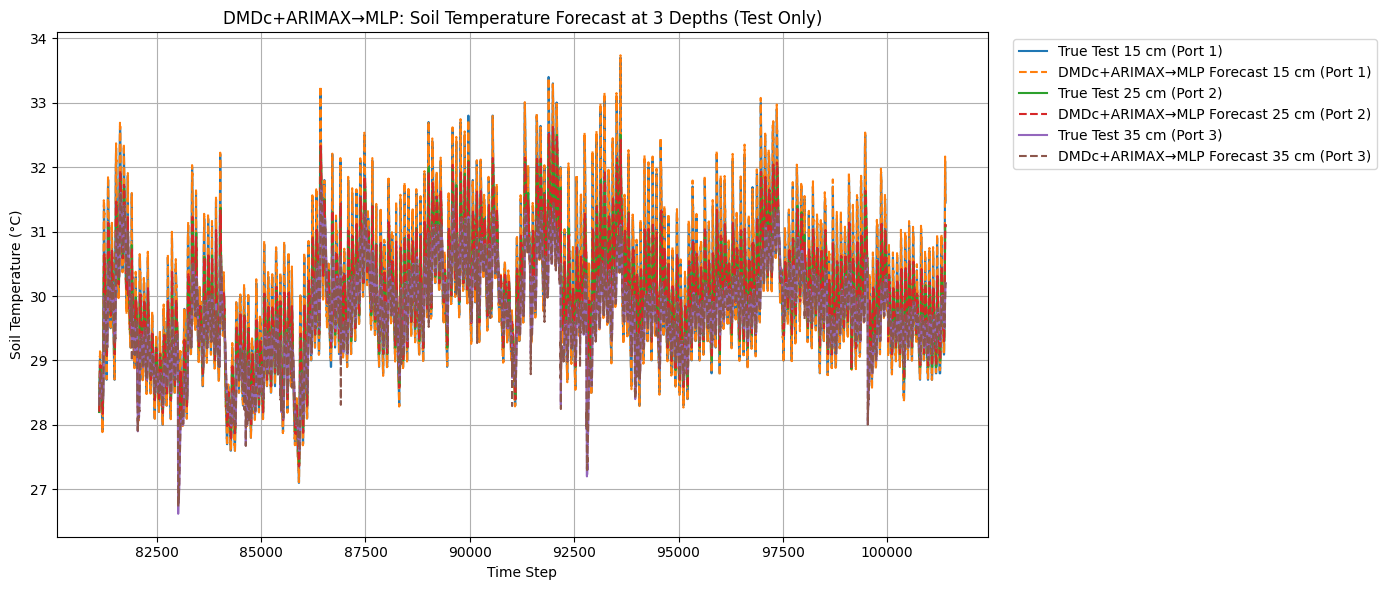


📊 DMDc+ARIMAX→MLP Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.045459 0.034851 0.115731
25 cm (Port 2)  Test 0.038801 0.027774 0.092519
35 cm (Port 3)  Test 0.042190 0.024729 0.083191


In [20]:
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Fill missing values ===
relevant_cols = [
    "Water Content_Port1", "Water Content_Port2", "Water Content_Port3",
    "Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"
]
train[relevant_cols] = train[relevant_cols].ffill().bfill()
test[relevant_cols] = test[relevant_cols].ffill().bfill()

# === Extract Inputs (U) and Outputs (Y) ===
def extract_io(df):
    U = df[["Water Content_Port1", "Water Content_Port2", "Water Content_Port3"]].values
    Y = df[["Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"]].values
    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# === Feature Creation with Lag ===
def create_arimax_mlp_features(U, Y, lags=2):
    X, y = [], []
    for t in range(lags, len(U)):
        past_features = []
        for lag in range(1, lags + 1):
            past_features.extend(U[t - lag])
            past_features.extend(Y[t - lag])
        X.append(past_features)
        y.append(Y[t])
    return np.array(X), np.array(y)

lags = 2
X_train_mlp, y_train_mlp = create_arimax_mlp_features(U_train, Y_train, lags)
X_test_mlp, y_test_mlp = create_arimax_mlp_features(U_test, Y_test, lags)

# === Double check for any NaNs
assert not np.isnan(X_train_mlp).any(), "NaNs in X_train_mlp"
assert not np.isnan(y_train_mlp).any(), "NaNs in y_train_mlp"
assert not np.isnan(X_test_mlp).any(), "NaNs in X_test_mlp"
assert not np.isnan(y_test_mlp).any(), "NaNs in y_test_mlp"

# === Train MLP Regressor ===
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1000, random_state=42)
mlp.fit(X_train_mlp, y_train_mlp)

# === Predict ===
y_pred_scaled = mlp.predict(X_test_mlp)
y_pred = Y_scaler.inverse_transform(y_pred_scaled)
y_test_orig = Y_scaler.inverse_transform(y_test_mlp)

# === Evaluation ===
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], y_pred[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# === Plot ===
n_train = len(Y_train)
n_test_mlp = len(y_test_orig)

plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_train + lags, n_train + lags + n_test_mlp), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_train + lags, n_train + lags + n_test_mlp), y_pred[:, i], '--', label=f'DMDc+ARIMAX→MLP Forecast {depth_labels[i]}')

plt.title("DMDc+ARIMAX→MLP: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
print("\n📊 DMDc+ARIMAX→MLP Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**DMDc+SVR->MLP**

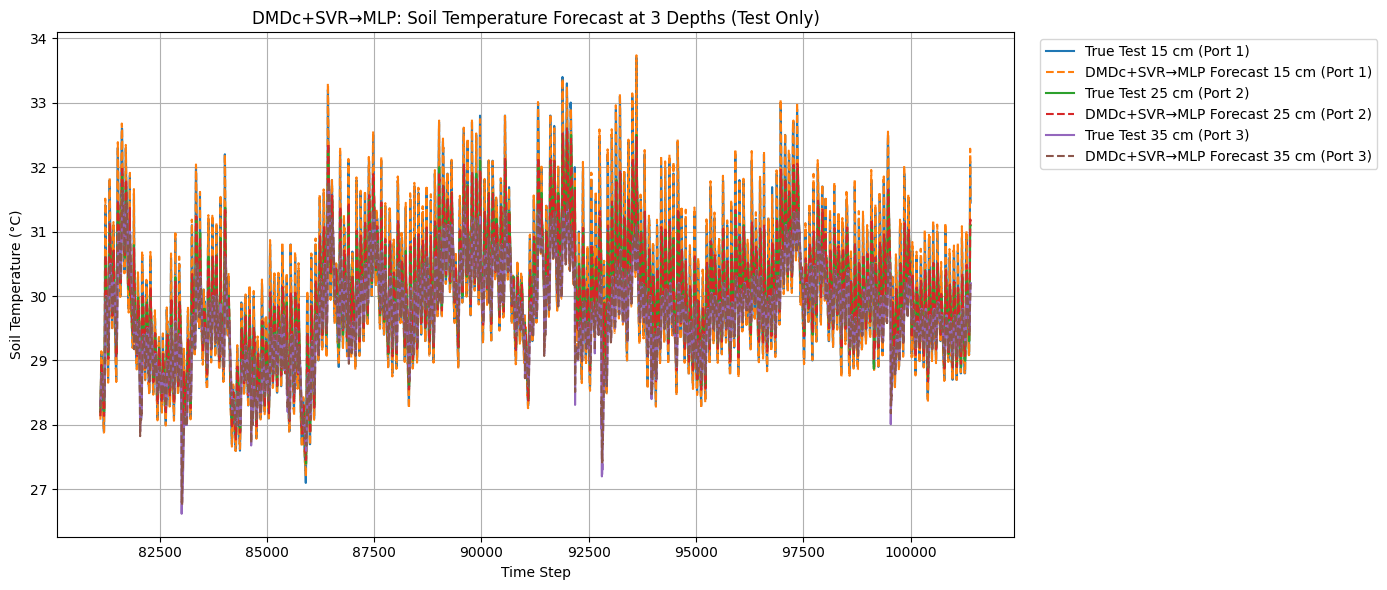


📊 DMDc+SVR→MLP Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.058487 0.044290 0.146897
25 cm (Port 2)  Test 0.044359 0.033654 0.112101
35 cm (Port 3)  Test 0.045668 0.027741 0.093677


In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Fill missing values ===
relevant_cols = [
    "Water Content_Port1", "Water Content_Port2", "Water Content_Port3",
    "Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"
]
train[relevant_cols] = train[relevant_cols].ffill().bfill()
test[relevant_cols] = test[relevant_cols].ffill().bfill()

# === Extract Inputs (U) and Outputs (Y) ===
def extract_io(df):
    U = df[[
        "Water Content_Port1",
        "Water Content_Port2",
        "Water Content_Port3"
    ]].values
    Y = df[[
        "Soil Temperature_Port1",
        "Soil Temperature_Port2",
        "Soil Temperature_Port3"
    ]].values
    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# === Feature Creation ===
def create_features(U, Y):
    X = np.hstack([U[:-1], Y[:-1]])
    y = Y[1:]
    return X, y

X_train_svr, y_train_svr = create_features(U_train, Y_train)
X_test_svr, y_test_svr = create_features(U_test, Y_test)

# === SVR Prediction (Intermediate Step) ===
y_pred_svr_train = np.zeros_like(y_train_svr)
y_pred_svr_test = np.zeros_like(y_test_svr)

for i in range(3):  # for each depth
    svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
    svr.fit(X_train_svr, y_train_svr[:, i])
    y_pred_svr_train[:, i] = svr.predict(X_train_svr)
    y_pred_svr_test[:, i] = svr.predict(X_test_svr)

# === Final MLP Stage ===
X_train_mlp = np.hstack([U_train[1:], y_pred_svr_train])
y_train_mlp = Y_train[1:]

X_test_mlp = np.hstack([U_test[1:], y_pred_svr_test])
y_test_mlp = Y_test[1:]

# === Train MLP Regressor ===
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1000, random_state=42)
mlp.fit(X_train_mlp, y_train_mlp)

# === Predict and Inverse Transform ===
y_pred_scaled = mlp.predict(X_test_mlp)
y_pred = Y_scaler.inverse_transform(y_pred_scaled)
y_test_orig = Y_scaler.inverse_transform(y_test_mlp)

# === Evaluation ===
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], y_pred[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# === Plot ===
n_train = len(Y_train)
n_test = len(y_test_orig)

plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_train + 1, n_train + 1 + n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_train + 1, n_train + 1 + n_test), y_pred[:, i], '--', label=f'DMDc+SVR→MLP Forecast {depth_labels[i]}')

plt.title("DMDc+SVR→MLP: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
print("\n📊 DMDc+SVR→MLP Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**DMDc+XGBoost->MLP**

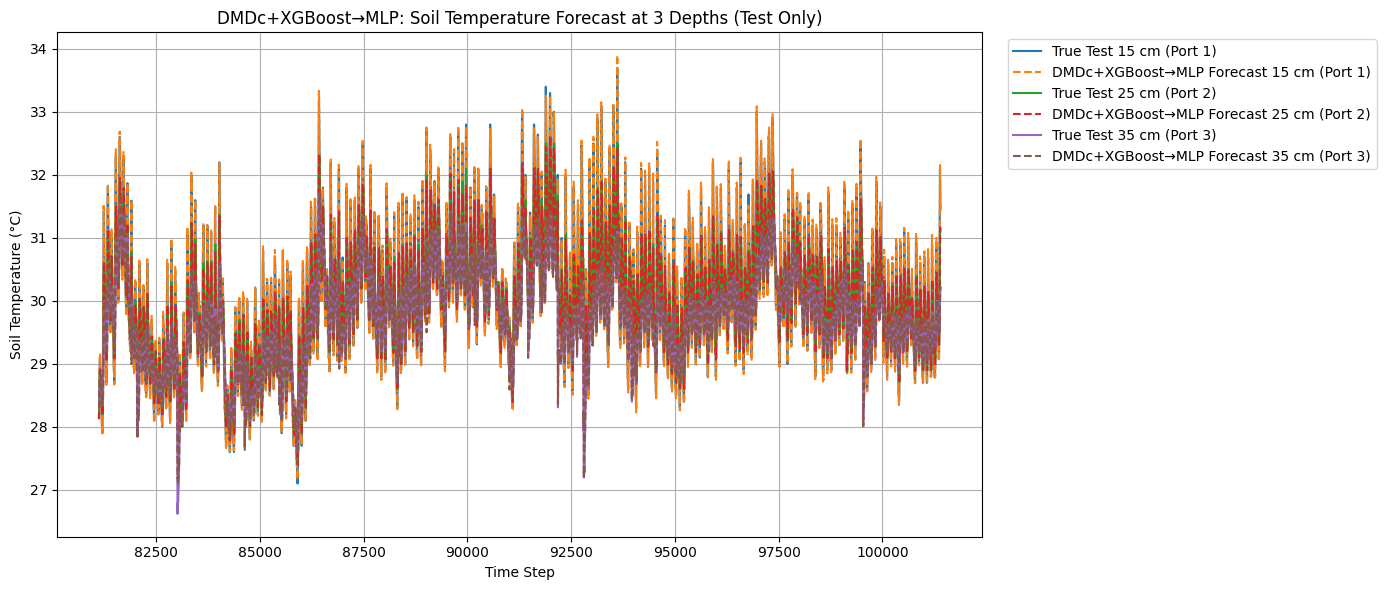


📊 DMDc+XGBoost→MLP Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.058206 0.044364 0.147031
25 cm (Port 2)  Test 0.038696 0.028796 0.095749
35 cm (Port 3)  Test 0.045767 0.026142 0.088195


In [26]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Fill missing and infinite values in relevant columns ===
relevant_cols = [
    "Water Content_Port1", "Water Content_Port2", "Water Content_Port3",
    "Soil Temperature_Port1", "Soil Temperature_Port2", "Soil Temperature_Port3"
]
for df in [train, test]:
    df[relevant_cols] = df[relevant_cols].replace([np.inf, -np.inf], np.nan)
    df[relevant_cols] = df[relevant_cols].ffill().bfill()

# === Extract Inputs (U) and Outputs (Y) ===
def extract_io(df):
    U = df[[
        "Water Content_Port1",
        "Water Content_Port2",
        "Water Content_Port3"
    ]].values

    Y = df[[
        "Soil Temperature_Port1",
        "Soil Temperature_Port2",
        "Soil Temperature_Port3"
    ]].values

    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# === Feature Construction ===
def create_features(U, Y):
    X = np.hstack([U[:-1], Y[:-1]])
    y = Y[1:]
    return X, y

X_train_xgb, y_train_xgb = create_features(U_train, Y_train)
X_test_xgb, y_test_xgb = create_features(U_test, Y_test)

# === Step 1: XGBoost Prediction ===
y_pred_xgb_train = np.zeros_like(y_train_xgb)
y_pred_xgb_test = np.zeros_like(y_test_xgb)

for i in range(3):  # For each depth
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
    xgb.fit(X_train_xgb, y_train_xgb[:, i])
    y_pred_xgb_train[:, i] = xgb.predict(X_train_xgb)
    y_pred_xgb_test[:, i] = xgb.predict(X_test_xgb)

# === Step 2: MLP on top of XGBoost outputs ===
X_train_mlp = np.hstack([U_train[1:], y_pred_xgb_train])
y_train_mlp = Y_train[1:]

X_test_mlp = np.hstack([U_test[1:], y_pred_xgb_test])
y_test_mlp = Y_test[1:]

mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1000, random_state=42)
mlp.fit(X_train_mlp, y_train_mlp)

# === Final Prediction ===
y_pred_scaled = mlp.predict(X_test_mlp)
y_pred = Y_scaler.inverse_transform(y_pred_scaled)
y_test_orig = Y_scaler.inverse_transform(y_test_mlp)

# === Evaluation ===
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], y_pred[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# === Plot Forecast ===
n_train = len(Y_train)
n_test = len(y_test_orig)

plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_train + 1, n_train + 1 + n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_train + 1, n_train + 1 + n_test), y_pred[:, i], '--', label=f'DMDc+XGBoost→MLP Forecast {depth_labels[i]}')

plt.title("DMDc+XGBoost→MLP: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
print("\n📊 DMDc+XGBoost→MLP Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**DMDc+XGBoost->ARIMAX**

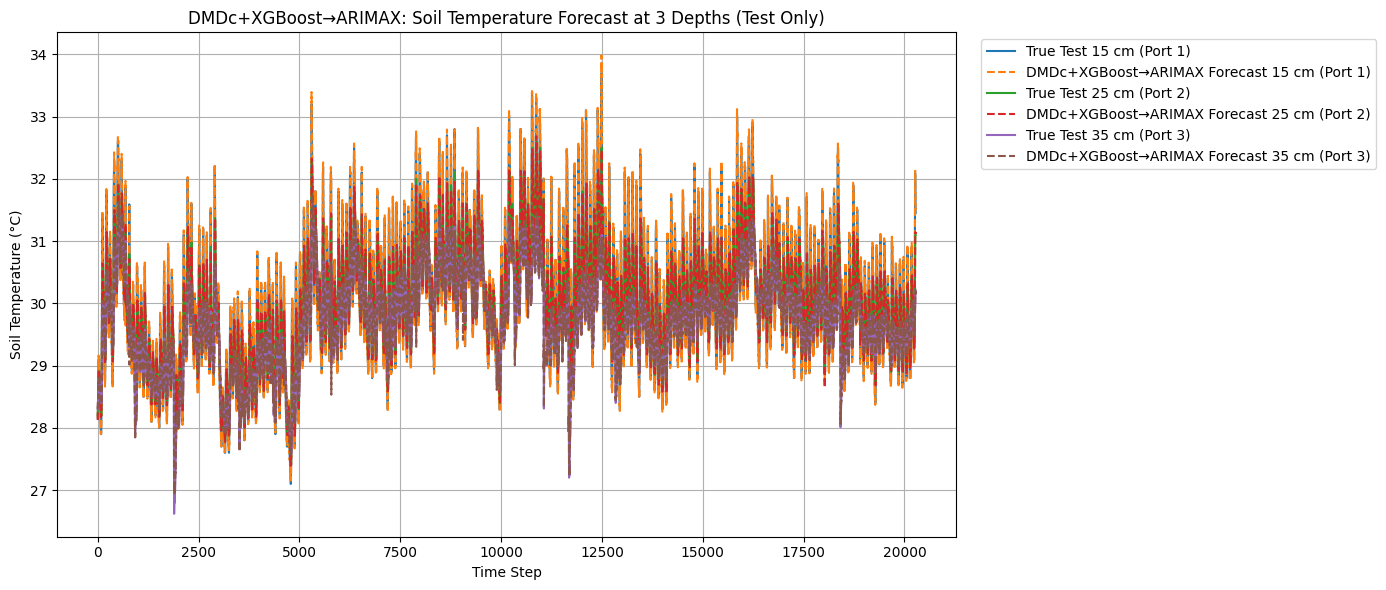


📊 DMDc+XGBoost→ARIMAX Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.047269 0.035708 0.118490
25 cm (Port 2)  Test 0.034892 0.025129 0.083612
35 cm (Port 3)  Test 0.041376 0.021621 0.073003


In [2]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Ensure datetime and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Extract Inputs (U) and Outputs (Y) ===
def extract_io(df):
    U = df[[
        "Water Content_Port1",
        "Water Content_Port2",
        "Water Content_Port3"
    ]].values

    Y = df[[
        "Soil Temperature_Port1",
        "Soil Temperature_Port2",
        "Soil Temperature_Port3"
    ]].values

    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# === Feature Construction ===
def create_features(U, Y):
    X = np.hstack([U[:-1], Y[:-1]])
    y = Y[1:]
    return X, y

X_train_xgb, y_train_xgb = create_features(U_train, Y_train)
X_test_xgb, y_test_xgb = create_features(U_test, Y_test)

# === Handle NaNs/Infs ===
mask_train = (
    np.isfinite(X_train_xgb).all(axis=1) &
    np.isfinite(y_train_xgb).all(axis=1)
)
X_train_xgb = X_train_xgb[mask_train]
y_train_xgb = y_train_xgb[mask_train]

mask_test = (
    np.isfinite(X_test_xgb).all(axis=1) &
    np.isfinite(y_test_xgb).all(axis=1)
)
X_test_xgb = X_test_xgb[mask_test]
y_test_xgb = y_test_xgb[mask_test]

# === Step 1: XGBoost Prediction ===
y_pred_xgb_test = np.zeros_like(y_test_xgb)

for i in range(3):  # For each depth
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
    xgb.fit(X_train_xgb, y_train_xgb[:, i])
    y_pred_xgb_test[:, i] = xgb.predict(X_test_xgb)

# === Step 2: ARIMAX on top of XGBoost predictions ===
y_pred_arimax = np.zeros_like(y_pred_xgb_test)

for i in range(3):
    endog = y_test_xgb[:, i]
    exog = y_pred_xgb_test[:, i].reshape(-1, 1)
    model = SARIMAX(endog, exog=exog, order=(1, 0, 0), enforce_stationarity=False, enforce_invertibility=False)
    results = model.fit(disp=False)
    y_pred_arimax[:, i] = results.fittedvalues

# === Inverse transform ===
y_pred = Y_scaler.inverse_transform(y_pred_arimax)
y_test_orig = Y_scaler.inverse_transform(y_test_xgb)

# === Evaluation ===
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], y_pred[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# === Plot Forecast ===
n_test = len(y_test_orig)
plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_test), y_pred[:, i], '--', label=f'DMDc+XGBoost→ARIMAX Forecast {depth_labels[i]}')

plt.title("DMDc+XGBoost→ARIMAX: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
print("\n📊 DMDc+XGBoost→ARIMAX Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))


**ARIMAX+ARIMAX->MLP**

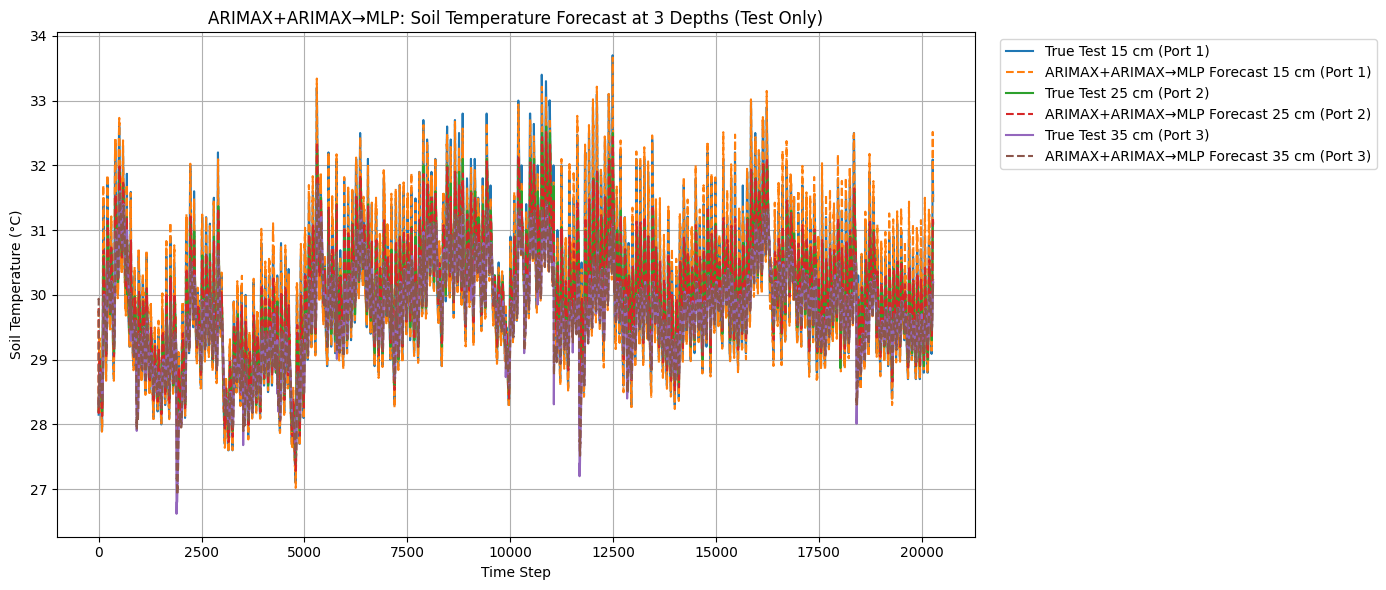

,Depth,Phase,RMSE,MAE,MAPE
0,15 cm (Port 1),Test,0.133845,0.096288,0.318467
1,25 cm (Port 2),Test,0.075942,0.054849,0.182559
2,35 cm (Port 3),Test,0.076206,0.050996,0.172150


In [5]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# Load datasets
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# Assign correct column names
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# Date formatting and sorting
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# Extract and clean features
def extract_io(df):
    U = df[[f"Water Content_Port{i}" for i in range(1, 4)]].replace([np.inf, -np.inf], np.nan).ffill().bfill().values
    Y = df[[f"Soil Temperature_Port{i}" for i in range(1, 4)]].replace([np.inf, -np.inf], np.nan).ffill().bfill().values
    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# Normalize
U_scaler = StandardScaler()
Y_scaler = StandardScaler()
U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# Ensure no inf/nan
def clean_scaled_data(U, Y):
    mask = np.isfinite(U).all(axis=1) & np.isfinite(Y).all(axis=1)
    return U[mask], Y[mask]

U_train, Y_train = clean_scaled_data(U_train, Y_train)
U_test, Y_test = clean_scaled_data(U_test, Y_test)

# Run ARIMAX for each port
def run_arimax(Y, U):
    pred = np.zeros_like(Y)
    for i in range(3):
        model = SARIMAX(Y[:, i], exog=U[:, i], order=(1, 0, 0), enforce_stationarity=False, enforce_invertibility=False)
        result = model.fit(disp=False)
        pred[:, i] = result.fittedvalues
    return pred

# First ARIMAX on Y using U
arimax_train_1 = run_arimax(Y_train, U_train)
arimax_test_1 = run_arimax(Y_test, U_test)

# Second ARIMAX on ARIMAX output using same U
arimax_train_2 = run_arimax(arimax_train_1, U_train)
arimax_test_2 = run_arimax(arimax_test_1, U_test)

# Prepare MLP inputs
X_train = np.hstack([U_train[1:], arimax_train_2[:-1]])
y_train = Y_train[1:]

X_test = np.hstack([U_test[1:], arimax_test_2[:-1]])
y_test = Y_test[1:]

# Train MLP
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', max_iter=1000, random_state=42)
mlp.fit(X_train, y_train)

# Predict
y_pred_scaled = mlp.predict(X_test)
y_pred = Y_scaler.inverse_transform(y_pred_scaled)
y_test_orig = Y_scaler.inverse_transform(y_test)

# Evaluate
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}
for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], y_pred[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# Plot results
n_test = len(y_test_orig)
plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_test), y_pred[:, i], '--', label=f'ARIMAX+ARIMAX→MLP Forecast {depth_labels[i]}')
plt.title("ARIMAX+ARIMAX→MLP: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

metrics_df



**ARIMAX+ARIMAX->ARIMAX**

/tmp/ipykernel_36/2578169734.py:38: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)
/tmp/ipykernel_36/2578169734.py:39: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='bfill', inplace=True)
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


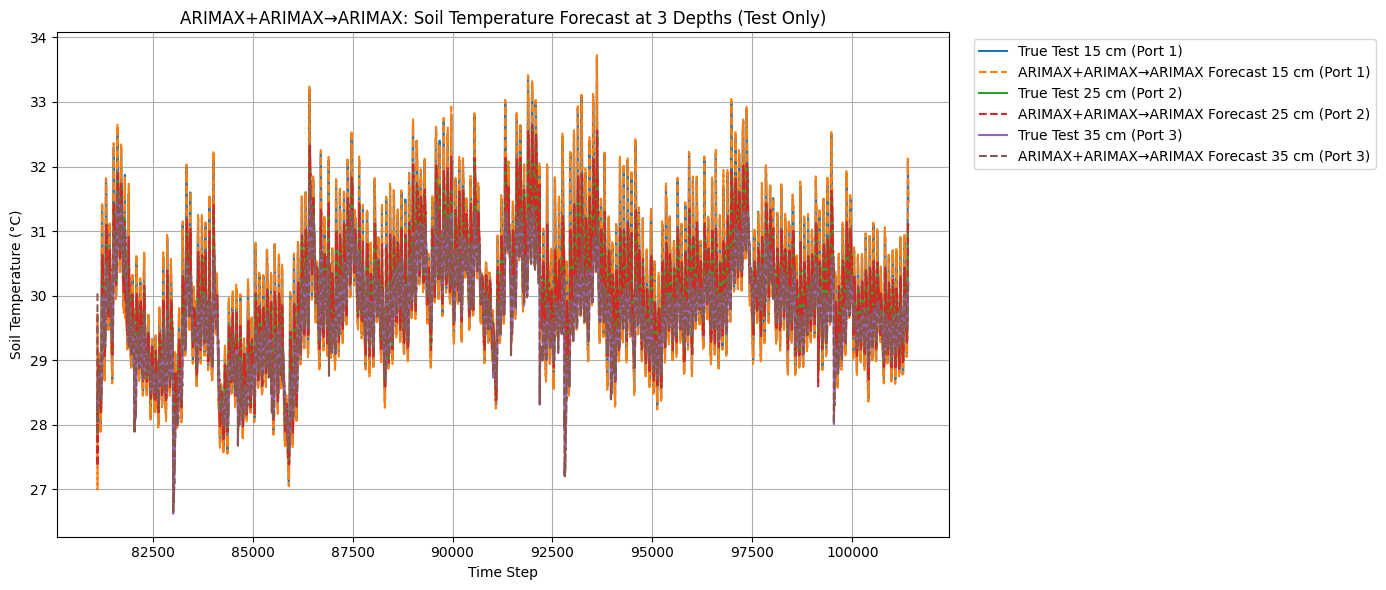


📊 ARIMAX+ARIMAX→ARIMAX Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.049382 0.035394 0.117581
25 cm (Port 2)  Test 0.042721 0.028205 0.093922
35 cm (Port 3)  Test 0.040506 0.018059 0.060862


In [7]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# === Load datasets ===
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# === Assign correct column names ===
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# === Timestamp parsing and sorting ===
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# === Extract inputs (U) and outputs (Y) ===
def extract_io(df):
    U = df[[f"Water Content_Port{i}" for i in range(1, 4)]].values
    Y = df[[f"Soil Temperature_Port{i}" for i in range(1, 4)]].values
    return U, Y

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

# === Clean data: replace inf/nan values ===
def safe_fill(arr):
    df = pd.DataFrame(arr)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(method='ffill', inplace=True)
    df.fillna(method='bfill', inplace=True)
    df.fillna(0, inplace=True)
    return df.values

U_train_raw = safe_fill(U_train_raw)
Y_train_raw = safe_fill(Y_train_raw)
U_test_raw = safe_fill(U_test_raw)
Y_test_raw = safe_fill(Y_test_raw)

# === Normalize ===
U_scaler = StandardScaler()
Y_scaler = StandardScaler()

U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# === ARIMAX function ===
def run_arimax(Y, U):
    preds = np.zeros_like(Y)
    for i in range(3):
        model = SARIMAX(Y[:, i], exog=U[:, i], order=(1,0,0), enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        preds[:, i] = res.fittedvalues
    return preds

# === First ARIMAX ===
intermediate_train = run_arimax(Y_train, U_train)
intermediate_test = run_arimax(Y_test, U_test)

# === Second ARIMAX ===
final_preds_scaled = run_arimax(Y_test, intermediate_test)
final_preds = Y_scaler.inverse_transform(final_preds_scaled)
y_test_orig = Y_scaler.inverse_transform(Y_test)

# === Evaluation ===
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], final_preds[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# === Plot ===
n_train = len(Y_train)
n_test = len(y_test_orig)
plt.figure(figsize=(14, 6))
for i in range(3):
    plt.plot(range(n_train + 1, n_train + 1 + n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_train + 1, n_train + 1 + n_test), final_preds[:, i], '--', label=f'ARIMAX+ARIMAX→ARIMAX Forecast {depth_labels[i]}')

plt.title("ARIMAX+ARIMAX→ARIMAX: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# === Display Results ===
print("\n📊 ARIMAX+ARIMAX→ARIMAX Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))



**DMDc+ARIMAX->ARIMAX**

/tmp/ipykernel_36/3553312867.py:34: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)
/tmp/ipykernel_36/3553312867.py:35: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='bfill', inplace=True)
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


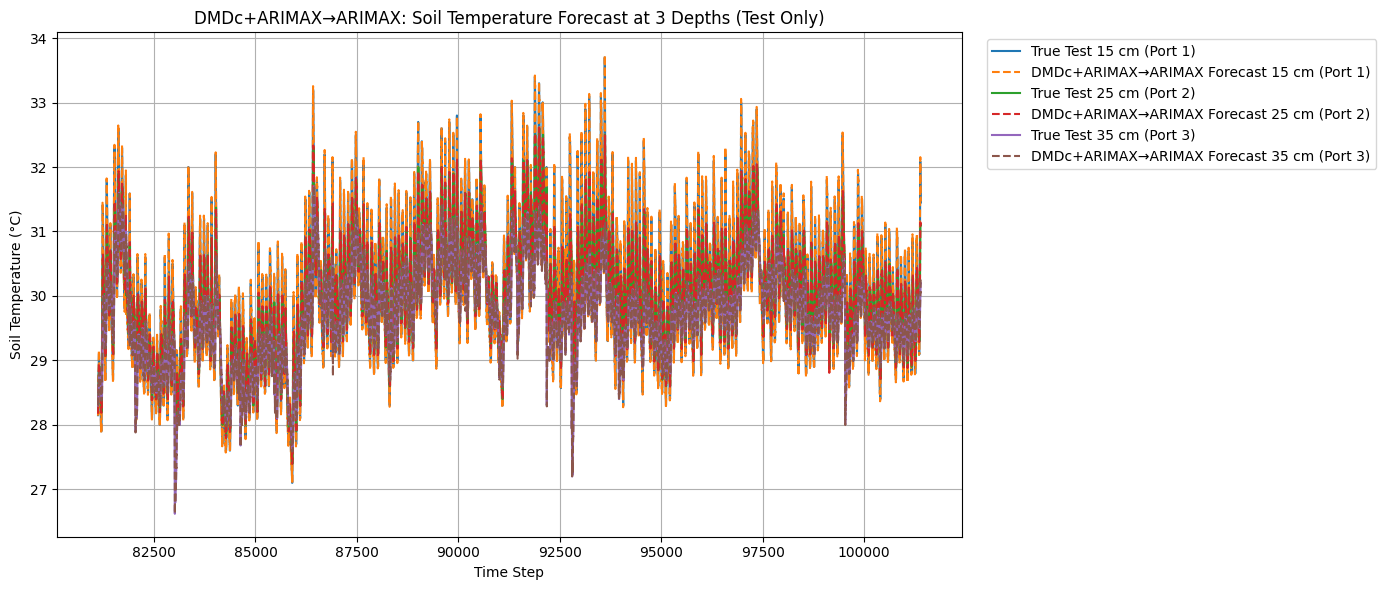


📊 DMDc+ARIMAX→ARIMAX Forecast Evaluation Metrics (Test Only):
         Depth Phase     RMSE      MAE     MAPE
15 cm (Port 1)  Test 0.045040 0.034306 0.113947
25 cm (Port 2)  Test 0.033626 0.024599 0.081909
35 cm (Port 3)  Test 0.038384 0.020521 0.069110


In [8]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# Load datasets
train = pd.read_csv("/kaggle/input/completedata/eahe_train.csv")
test = pd.read_csv("/kaggle/input/completedata/eahe_test.csv")

# Assign proper column names
column_names = ['Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
 'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
 'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2','% Battery Percent','mV Battery Voltage',
 'kPa Reference Pressure', 'Â°C Logger Temperature']
train.columns = test.columns = column_names

# Date handling
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
    df.sort_values("Timestamp", inplace=True)
    df.reset_index(drop=True, inplace=True)

# I/O extraction
def extract_io(df):
    U = df[[f"Water Content_Port{i}" for i in range(1, 4)]].values
    Y = df[[f"Soil Temperature_Port{i}" for i in range(1, 4)]].values
    return U, Y

def safe_fill(arr):
    df = pd.DataFrame(arr)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(method='ffill', inplace=True)
    df.fillna(method='bfill', inplace=True)
    df.fillna(0, inplace=True)
    return df.values

U_train_raw, Y_train_raw = extract_io(train)
U_test_raw, Y_test_raw = extract_io(test)

U_train_raw = safe_fill(U_train_raw)
Y_train_raw = safe_fill(Y_train_raw)
U_test_raw = safe_fill(U_test_raw)
Y_test_raw = safe_fill(Y_test_raw)

# Normalization
U_scaler = StandardScaler()
Y_scaler = StandardScaler()
U_train = U_scaler.fit_transform(U_train_raw)
Y_train = Y_scaler.fit_transform(Y_train_raw)
U_test = U_scaler.transform(U_test_raw)
Y_test = Y_scaler.transform(Y_test_raw)

# DMDc Feature Construction
def dmdc_features(U, Y):
    X = np.hstack([U[:-1], Y[:-1]])
    Y_next = Y[1:]
    return X, Y_next

X_train_dmdc, Y_train_dmdc = dmdc_features(U_train, Y_train)
X_test_dmdc, Y_test_dmdc = dmdc_features(U_test, Y_test)

# Step 1: ARIMAX on top of DMDc features
def arimax_on_dmdc(Y, X):
    preds = np.zeros_like(Y)
    for i in range(3):
        model = SARIMAX(Y[:, i], exog=X, order=(1, 0, 0), enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        preds[:, i] = res.fittedvalues
    return preds

intermediate_train_preds = arimax_on_dmdc(Y_train_dmdc, X_train_dmdc)
intermediate_test_preds = arimax_on_dmdc(Y_test_dmdc, X_test_dmdc)

# Step 2: Final ARIMAX using intermediate predictions
def arimax_final(Y, inter_preds):
    preds = np.zeros_like(Y)
    for i in range(3):
        model = SARIMAX(Y[:, i], exog=inter_preds[:, i], order=(1, 0, 0), enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        preds[:, i] = res.fittedvalues
    return preds

final_preds_scaled = arimax_final(Y_test_dmdc, intermediate_test_preds)
final_preds = Y_scaler.inverse_transform(final_preds_scaled)
y_test_orig = Y_scaler.inverse_transform(Y_test_dmdc)

# Evaluation
def compute_metrics(true, pred):
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae = mean_absolute_error(true, pred)
    mape = np.mean(np.abs((true - pred) / true)) * 100
    return rmse, mae, mape

depth_labels = ['15 cm (Port 1)', '25 cm (Port 2)', '35 cm (Port 3)']
metrics = {"Depth": [], "Phase": [], "RMSE": [], "MAE": [], "MAPE": []}

for i in range(3):
    rmse, mae, mape = compute_metrics(y_test_orig[:, i], final_preds[:, i])
    metrics["Depth"].append(depth_labels[i])
    metrics["Phase"].append("Test")
    metrics["RMSE"].append(rmse)
    metrics["MAE"].append(mae)
    metrics["MAPE"].append(mape)

metrics_df = pd.DataFrame(metrics)

# Plot
plt.figure(figsize=(14, 6))
n_train = len(Y_train)
n_test = len(y_test_orig)
for i in range(3):
    plt.plot(range(n_train + 1, n_train + 1 + n_test), y_test_orig[:, i], label=f'True Test {depth_labels[i]}')
    plt.plot(range(n_train + 1, n_train + 1 + n_test), final_preds[:, i], '--', label=f'DMDc+ARIMAX→ARIMAX Forecast {depth_labels[i]}')

plt.title("DMDc+ARIMAX→ARIMAX: Soil Temperature Forecast at 3 Depths (Test Only)")
plt.xlabel("Time Step")
plt.ylabel("Soil Temperature (°C)")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# Display results
print("\n📊 DMDc+ARIMAX→ARIMAX Forecast Evaluation Metrics (Test Only):")
print(metrics_df.to_string(index=False))
